In [1]:
# ============================================================
# 06_River_Analysis.ipynb | Cell 1: setup, main stem, uniform resampling, confluences
# ============================================================
import importlib
import numpy as np
from scipy import ndimage
from scipy.spatial import cKDTree
from pyproj import Transformer
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from matplotlib.collections import LineCollection
import utils
importlib.reload(utils)
from utils import *

P = get_paths()
ws = WatershedGrid(P.RAS / "watershed_mask.tif", P.VEC / "watershed_boundary.gpkg",
                   P.VEC / "outlet_snapped.shp")
H, W = ws.mask.shape
tf = ws.transform
to_ll = Transformer.from_crs(ws.crs, 4326, always_xy=True)
print(ws)

# ---------- parameters shared by several cells ----------
DS_M         = 30.0     # uniform spacing along the channel (m)
SMOOTH_Z_M   = 300.0    # elevation smoothing window (m)
SLOPE_WIN_M  = 1000.0   # window for the channel gradient (m)
THETA_REF    = 0.45     # reference concavity for the steepness index ksn
MOD_THRESH_M = 20.0     # |conditioned - original DEM| above this flags a DEM-modified cell (m)
MOD_BUFFER_M = 500.0    # flagged zones are widened by this distance on each side (m)
TRIB_MIN_KM2 = 100.0    # a tributary inflow of at least this area counts as a major confluence (km2)


# ---------- helpers ----------
def read_grid(path):
    with rasterio.open(path) as s:
        a = s.read(1).astype("float32"); nd = s.nodata
    if nd is not None:
        a[a == nd] = np.nan
    return a


def secant_slope(z, ds, win_m):
    """Gradient (m/m, positive downstream) from the elevation drop across a centred window."""
    n = len(z); h = max(1, int(round(win_m / ds / 2)))
    i = np.arange(n); lo = np.clip(i - h, 0, n - 1); hi = np.clip(i + h, 0, n - 1)
    return (z[lo] - z[hi]) / np.maximum((hi - lo) * ds, ds)


def hillshade_for_plot():
    hs = read_grid(P.RAS / "hillshade.tif")
    assert hs.shape == (H, W), "hillshade.tif is on a different grid - rerun notebook 02"
    step = max(1, int(np.ceil(max(hs.shape) / 2500)))
    return hs[::step, ::step]


gsub = gpd.read_file(P.VEC / "subcatchments.gpkg")
N_SUB = len(gsub)


def choropleth(col, fname, title, label, cmap="YlOrRd", vmin=None, vmax=None, fmt="{:.0f}"):
    """Subcatchment polygons coloured by a gsub column, with ids and values printed on each unit."""
    vals = gsub[col].values.astype(float)
    lo = np.nanmin(vals) if vmin is None else vmin
    hi = np.nanmax(vals) if vmax is None else vmax
    e = ws.extent
    fig, ax = plt.subplots(figsize=(8.6, float(np.clip(8 * (e[3] - e[2]) / (e[1] - e[0]), 5, 11))))
    gsub.plot(ax=ax, column=col, cmap=cmap, vmin=lo, vmax=hi, edgecolor="0.25", linewidth=0.4, legend=False)
    cax = make_axes_locatable(ax).append_axes("right", size="3%", pad=0.12)
    cb = fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=mcolors.Normalize(vmin=lo, vmax=hi)), cax=cax)
    cb.set_label(label, fontsize=7.5); cb.ax.tick_params(labelsize=6.5)
    for p, i, v in zip(gsub.representative_point(), gsub["sub_id"], vals):
        ax.text(p.x, p.y, f"{i}\n{fmt.format(v)}" if np.isfinite(v) else str(i),
                fontsize=5, ha="center", va="center")
    map_furniture(ax, ws, title)
    fig.savefig(P.FIG / fname, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show(); plt.close(fig)


# ---------- main stem from notebook 04 ----------
prof = pd.read_csv(P.TAB / "04_main_stem_profile.csv")
need = ["x", "y", "elev_original_m", "elev_conditioned_m", "upstr_area_km2", "order"]
missing = [c for c in need if c not in prof.columns]
assert not missing, f"04_main_stem_profile.csv lacks {missing} - rerun notebook 04 Cell 4"
if prof.elev_conditioned_m.iloc[0] < prof.elev_conditioned_m.iloc[-1]:        # make it run head -> outlet
    prof = prof.iloc[::-1].reset_index(drop=True)
x_raw, y_raw = prof.x.values, prof.y.values
s_raw = np.concatenate([[0.0], np.cumsum(np.hypot(np.diff(x_raw), np.diff(y_raw)))])
L_TOTAL = float(s_raw[-1])
if ws.outlet is not None:
    gap = float(np.hypot(x_raw[-1] - ws.outlet[0], y_raw[-1] - ws.outlet[1]))
    print(f"Main stem end to snapped outlet: {gap:.0f} m")
    assert gap < 3 * ws.res[0], "main stem does not end at the outlet - rerun notebook 04 Cell 4"

# ---------- uniform resampling ----------
s = np.arange(0.0, L_TOTAL, DS_M)
if L_TOTAL - s[-1] > 1.0:
    s = np.append(s, L_TOTAL)
N = len(s)
ip = lambda v: np.interp(s, s_raw, np.asarray(v, dtype=float))
river = pd.DataFrame({"s_m": s, "d_out_m": L_TOTAL - s, "x": ip(x_raw), "y": ip(y_raw),
                      "z_orig": ip(prof.elev_original_m), "z_cond": ip(prof.elev_conditioned_m),
                      "area_km2": ip(prof.upstr_area_km2),
                      "order": np.rint(ip(prof["order"])).astype(int)})
river["lon"], river["lat"] = to_ll.transform(river.x.values, river.y.values)

z_c = river.z_cond.values
rises = int((np.diff(z_c) > 0.5).sum())
print(f"\nMain stem: {L_TOTAL / 1000:,.1f} km | {N:,} points at {DS_M:.0f} m")
print(f"Elevation: head {z_c[0]:,.0f} m -> outlet {z_c[-1]:,.0f} m (conditioned DEM) | drop {z_c[0] - z_c[-1]:,.0f} m "
      f"| mean gradient {(z_c[0] - z_c[-1]) / L_TOTAL:.4f} m/m")
print(f"Upstream area: head {river.area_km2.iloc[0]:.1f} km2 -> outlet {river.area_km2.iloc[-1]:,.1f} km2")
print(f"Conditioned profile rises downstream at {rises} of {N - 1} steps (expect 0)")

# ---------- major confluences (a jump in upstream area along the main stem) ----------
a_raw = prof.upstr_area_km2.values
jump = np.diff(a_raw)
ci = np.flatnonzero(jump >= TRIB_MIN_KM2)
conf = pd.DataFrame({"dist_from_outlet_km": (L_TOTAL - s_raw[ci + 1]) / 1000,
                     "main_area_before_km2": a_raw[ci], "tributary_area_km2": jump[ci],
                     "x": x_raw[ci + 1], "y": y_raw[ci + 1],
                     "elev_m": prof.elev_conditioned_m.values[ci + 1]})
conf["tributary_to_main_ratio"] = conf.tributary_area_km2 / conf.main_area_before_km2
conf["tributary_larger_than_main"] = conf.tributary_to_main_ratio > 1
lon_c, lat_c = to_ll.transform(conf.x.values, conf.y.values)
conf["lon"], conf["lat"] = np.asarray(lon_c), np.asarray(lat_c)
conf = conf.sort_values("dist_from_outlet_km").reset_index(drop=True)
conf.insert(0, "confluence_id", np.arange(1, len(conf) + 1))
conf = conf.round(3)
save_table(conf, P.TAB / "06_confluences.csv")
print(f"Major confluences (tributary >= {TRIB_MIN_KM2:.0f} km2): {len(conf)} "
      f"| tributary larger than the main stem above it: {int(conf.tributary_larger_than_main.sum())}")
display(conf.head(12))

WatershedGrid(window=(6018, 5247), cells=13,631,535, area=11,873.1 km2, res=29.51 m)
Main stem end to snapped outlet: 0 m

Main stem: 417.9 km | 13,931 points at 30 m
Elevation: head 5,636 m -> outlet 184 m (conditioned DEM) | drop 5,452 m | mean gradient 0.0130 m/m
Upstream area: head 6.3 km2 -> outlet 11,873.1 km2
Conditioned profile rises downstream at 0 of 13930 steps (expect 0)
Major confluences (tributary >= 100 km2): 19 | tributary larger than the main stem above it: 0


,confluence_id,dist_from_outlet_km,main_area_before_km2,tributary_area_km2,x,y,elev_m,tributary_to_main_ratio,tributary_larger_than_main,lon,lat
0,1,80.410,11048.736,227.367,790025.415,3086446.793,302.974,0.021,False,83.946,27.871
1,2,81.280,10941.992,105.801,789494.186,3087096.073,302.984,0.010,False,83.940,27.877
2,3,90.064,10697.883,198.517,783178.460,3088188.044,318.974,0.019,False,83.876,27.889
3,4,160.667,9669.618,597.691,740148.891,3092349.340,457.997,0.062,False,83.441,27.935
4,5,166.738,7642.981,1994.470,743277.241,3096569.661,467.996,0.261,False,83.473,27.972
5,6,181.251,7107.578,480.636,754285.491,3097602.607,499.999,0.068,False,83.585,27.979
6,7,186.304,6959.049,138.305,756174.306,3101144.135,520.996,0.020,False,83.605,28.011
7,8,220.120,5907.132,675.976,762076.854,3122540.869,671.999,0.114,False,83.670,28.203
8,9,230.740,5746.676,117.558,756764.561,3128118.776,727.999,0.020,False,83.617,28.254
9,10,244.303,4554.695,1094.291,751835.934,3137592.365,822.999,0.240,False,83.569,28.340


DEM-modified reaches (|conditioned - original| > 20 m, widened by 500 m): 39 | 89.8 km (21.5 % of the main stem)
Largest change: -421 m at 346.2 km from the outlet (83.838 E, 28.966 N)


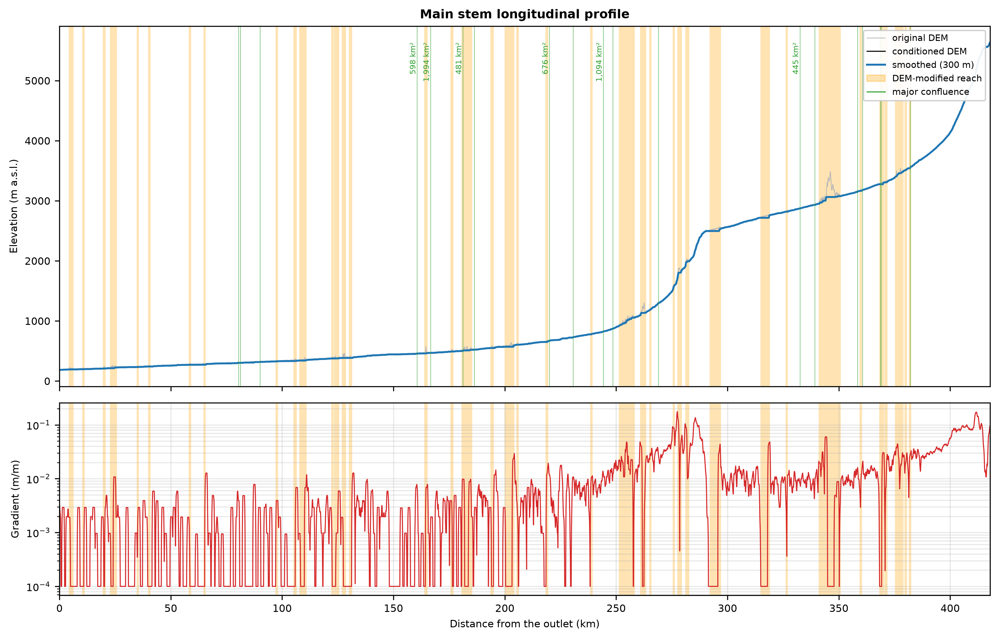


Steepest 10 km blocks:


,block,from_km,to_km,length_km,elev_up_m,elev_down_m,drop_m,gradient_m_per_m,mean_area_km2
41,41,410.0114,417.8714,7.86,5633.3504,4971.0763,662.2741,0.0843,16.1037
40,40,400.0214,409.9814,9.96,4968.5577,4136.6737,831.8840,0.0835,35.0432
28,28,280.0214,289.9814,9.96,2488.8231,1868.4481,620.3750,0.0623,3525.5282
27,27,270.0014,279.9914,9.99,1867.4027,1316.8062,550.5965,0.0551,3611.6917
39,39,390.0014,399.9914,9.99,4134.7678,3767.6099,367.1579,0.0368,115.6899
38,38,380.0114,389.9714,9.96,3766.9154,3508.9976,257.9179,0.0259,366.7745


In [2]:
# ============================================================
# Cell 2: longitudinal profile, channel gradient, DEM-modified reaches, 10 km blocks
# ============================================================
BLOCK_KM = 10

z_o, z_c = river.z_orig.values, river.z_cond.values
n_sm = max(3, int(round(SMOOTH_Z_M / DS_M)))
z_s = ndimage.uniform_filter1d(z_c, size=n_sm, mode="nearest")
S = secant_slope(z_s, DS_M, SLOPE_WIN_M)

dz = z_c - z_o
mod = np.abs(dz) > MOD_THRESH_M
if mod.any():
    nb = int(round(MOD_BUFFER_M / DS_M))
    mod = ndimage.binary_dilation(mod, structure=np.ones(2 * nb + 1, dtype=bool))
lab_m, n_mod = ndimage.label(mod)
print(f"DEM-modified reaches (|conditioned - original| > {MOD_THRESH_M:.0f} m, widened by {MOD_BUFFER_M:.0f} m): "
      f"{n_mod} | {mod.sum() * DS_M / 1000:,.1f} km ({100 * mod.mean():.1f} % of the main stem)")
if mod.any():
    k_ = int(np.argmax(np.abs(dz)))
    print(f"Largest change: {dz[k_]:+.0f} m at {river.d_out_m.iloc[k_] / 1000:,.1f} km from the outlet "
          f"({river.lon.iloc[k_]:.3f} E, {river.lat.iloc[k_]:.3f} N)")

river["z_smooth"] = z_s
river["gradient"] = S
river["dz_cond_minus_orig"] = dz
river["dem_modified"] = mod
river["block"] = (river.d_out_m.values // (BLOCK_KM * 1000)).astype(int)

# ---------- figure ----------
x_km = river.d_out_m.values / 1000
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1.6], "hspace": 0.06})
ax1.plot(x_km, z_o, color="0.72", lw=0.6, label="original DEM")
ax1.plot(x_km, z_c, color="k", lw=0.8, label="conditioned DEM")
ax1.plot(x_km, z_s, color="tab:blue", lw=1.5, label=f"smoothed ({SMOOTH_Z_M:.0f} m)")
for k in range(1, n_mod + 1):
    ii = np.flatnonzero(lab_m == k)
    for ax in (ax1, ax2):
        ax.axvspan(x_km[ii].min(), x_km[ii].max(), color="orange", alpha=0.3, lw=0)
ymax = float(np.nanmax(z_o))
for _, c in conf.iterrows():
    ax1.axvline(c.dist_from_outlet_km, color="tab:green", lw=0.5, alpha=0.6)
for _, c in conf.nlargest(6, "tributary_area_km2").iterrows():
    ax1.text(c.dist_from_outlet_km, ymax, f" {c.tributary_area_km2:,.0f} km²", rotation=90,
             va="top", ha="right", fontsize=6, color="tab:green")
ax1.legend(handles=ax1.get_lines()[:3] + [Patch(color="orange", alpha=0.3, label="DEM-modified reach"),
                                          Line2D([0], [0], color="tab:green", lw=0.8, label="major confluence")],
           loc="upper right", fontsize=7, framealpha=0.92)
ax1.set_ylabel("Elevation (m a.s.l.)")
ax1.set_title("Main stem longitudinal profile", fontweight="bold")
ax2.semilogy(x_km, np.maximum(S, 1e-4), color="tab:red", lw=0.8)
ax2.set_ylabel("Gradient (m/m)")
ax2.set_xlabel("Distance from the outlet (km)")
ax2.set_xlim(0, x_km.max())
ax2.grid(alpha=0.3, which="both")
fig.savefig(P.FIG / "06_longitudinal_profile.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

# ---------- 10 km blocks (preview; the final table is written in Cell 7) ----------
rows = []
for b, gb in river.groupby("block"):
    if len(gb) < 3:
        continue
    L_ = float(gb.d_out_m.max() - gb.d_out_m.min())
    zu, zd = float(gb.z_smooth.iloc[0]), float(gb.z_smooth.iloc[-1])
    rows.append(dict(block=int(b), from_km=gb.d_out_m.min() / 1000, to_km=gb.d_out_m.max() / 1000,
                     length_km=L_ / 1000, elev_up_m=zu, elev_down_m=zd, drop_m=zu - zd,
                     gradient_m_per_m=(zu - zd) / L_, mean_area_km2=gb.area_km2.mean()))
blocks = pd.DataFrame(rows).round(4)
print(f"\nSteepest {BLOCK_KM} km blocks:")
display(blocks.sort_values("gradient_m_per_m", ascending=False).head(6))

Slope-area fit (8,983 points, 21 bins): concavity theta = 0.41 | ks = 75 | R2 = 0.72
  (bedrock rivers usually give theta of about 0.3-0.7; knickzones, glacial reaches and DEM artefacts can pull it outside that range)
ksn (theta_ref = 0.45): median 107 | p90 362 | max 3,215  (units m^0.9)


,kz_id,lip_dist_from_outlet_km,base_dist_from_outlet_km,length_km,drop_m,gradient_m_per_m,ksn_mean,baseline_ksn,ksn_ratio_max,area_lip_km2,elev_lip_m,elev_base_m,lon_lip,lat_lip,dem_modified_frac,kz_class,likely_artefact
0,1,205.201,203.341,1.89,31.852,0.017,439.949,64.332,11.387,6773.371,602.845,570.993,83.611,28.114,0.571,minor,True
1,2,255.001,254.431,0.60,32.426,0.054,910.205,354.725,2.780,4125.783,1008.255,975.828,83.599,28.415,1.000,minor,True
2,3,261.301,260.581,0.75,42.295,0.056,892.052,363.092,2.578,4079.610,1133.977,1091.682,83.627,28.459,0.840,minor,True
3,4,276.031,275.251,0.81,75.067,0.093,1751.113,822.122,2.164,3592.593,1579.550,1504.483,83.637,28.559,0.889,minor,True
4,5,278.011,277.051,0.99,164.660,0.166,2747.318,992.552,3.239,3586.346,1803.718,1639.058,83.644,28.573,0.606,major,True
5,6,287.251,284.881,2.40,269.683,0.112,2156.783,1023.443,2.485,3473.104,2362.658,2092.975,83.619,28.632,0.000,major,False
6,7,297.271,295.801,1.50,45.779,0.031,541.289,121.873,6.201,3376.229,2542.771,2496.992,83.622,28.690,0.920,minor,True
7,8,319.291,318.151,1.17,48.102,0.041,722.824,117.764,8.136,3027.844,2765.096,2716.994,83.760,28.793,0.846,minor,True
8,9,344.761,343.651,1.14,60.958,0.053,812.302,161.637,6.850,2113.866,3062.952,3001.994,83.832,28.956,1.000,minor,True


Knickzones: 9 (2 major, 8 flagged as DEM artefacts) | drop in the others: 270 m = 5 % of the total main stem drop


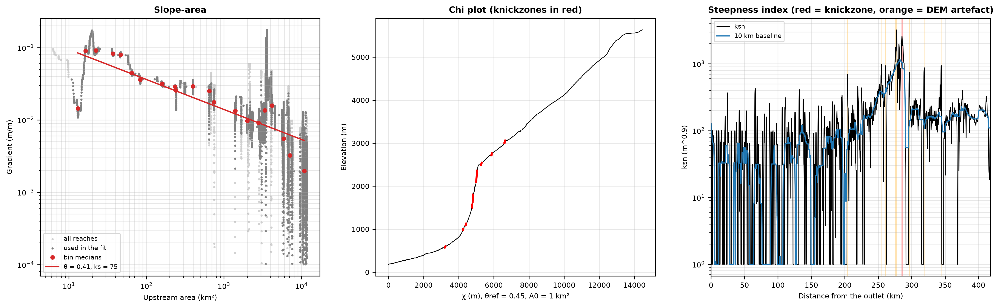

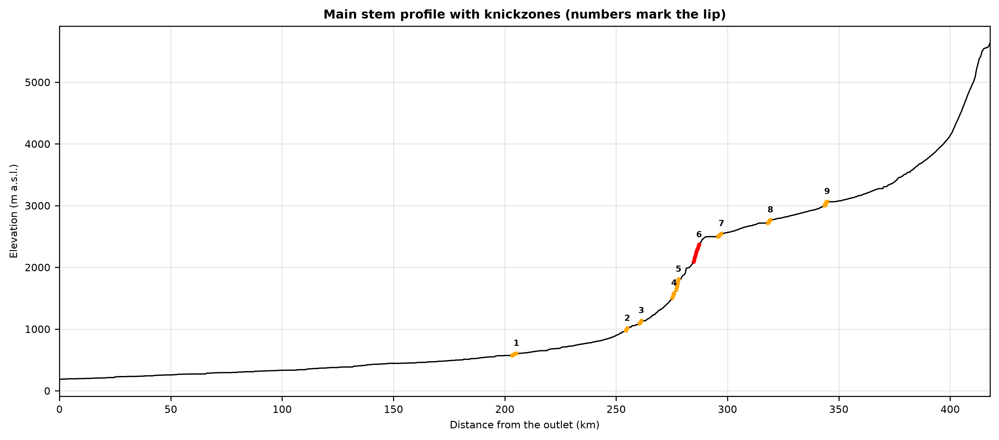

In [3]:
# ============================================================
# Cell 3: slope-area fit, steepness index (ksn), chi, knickzones
# ============================================================
A_MIN_REG_KM2 = 10.0     # slope-area fit uses reaches draining at least this area
N_BINS        = 25       # log bins of drainage area for the fit
KSN_MED_M     = 500.0    # median filter on ksn (m)
BASE_WIN_KM   = 10.0     # window of the running-median ksn baseline (km)
KZ_RATIO      = 2.0      # knickzone: ksn at least this multiple of the baseline
KZ_MIN_LEN_M  = 500.0
KZ_MIN_DROP_M = 30.0
KZ_MERGE_M    = 500.0    # gaps shorter than this between steep runs are closed
A_MIN_KZ_KM2  = 20.0     # ignore headwater reaches below this drainage area
KZ_MAJOR_DROP_M = 100.0

x, y = river.x.values, river.y.values
d_out, area = river.d_out_m.values, river.area_km2.values
z_s, S, mod = river.z_smooth.values, river.gradient.values, river.dem_modified.values.astype(bool)
x_km = d_out / 1000
N = len(river)
A_m2 = area * 1e6

# ---------- slope-area regression on log-binned medians ----------
use = (area >= A_MIN_REG_KM2) & (S > 1e-4) & ~mod
la, ls = np.log10(A_m2[use]), np.log10(S[use])
edges = np.linspace(la.min(), la.max(), N_BINS + 1)
bi = np.clip(np.digitize(la, edges) - 1, 0, N_BINS - 1)
ba, bs = [], []
for k in range(N_BINS):
    m_ = bi == k
    if m_.sum() >= 5:
        ba.append(np.median(la[m_])); bs.append(np.median(ls[m_]))
ba, bs = np.array(ba), np.array(bs)
assert len(ba) >= 4, "too few bins for the slope-area fit"
fit = np.polyfit(ba, bs, 1)
theta, ks = float(-fit[0]), float(10 ** fit[1])
r2 = float(np.corrcoef(ba, bs)[0, 1] ** 2)
print(f"Slope-area fit ({use.sum():,} points, {len(ba)} bins): concavity theta = {theta:.2f} | "
      f"ks = {ks:,.0f} | R2 = {r2:.2f}")
print("  (bedrock rivers usually give theta of about 0.3-0.7; knickzones, glacial reaches and "
      "DEM artefacts can pull it outside that range)")

# ---------- steepness index and chi ----------
ksn_raw = S * A_m2 ** THETA_REF
msize = int(round(KSN_MED_M / DS_M)) | 1
ksn = ndimage.median_filter(ksn_raw, size=msize, mode="nearest")
bsize = int(round(BASE_WIN_KM * 1000 / DS_M)) | 1
base = ndimage.median_filter(ksn, size=bsize, mode="nearest")
ratio = ksn / np.maximum(base, 1e-6)
integrand = (1e6 / A_m2) ** THETA_REF * DS_M          # reference area A0 = 1 km2
chi = np.cumsum(integrand[::-1])[::-1]
chi = chi - chi[-1]                                    # chi = 0 at the outlet
print(f"ksn (theta_ref = {THETA_REF}): median {np.median(ksn):,.0f} | p90 {np.percentile(ksn, 90):,.0f} "
      f"| max {ksn.max():,.0f}  (units m^{2 * THETA_REF:.1f})")

# ---------- knickzones: runs where ksn is far above its running baseline ----------
cand = (ratio >= KZ_RATIO) & (area >= A_MIN_KZ_KM2)
ncl = max(1, int(round(KZ_MERGE_M / DS_M)))
if cand.any():
    cand = ndimage.binary_closing(cand, structure=np.ones(ncl, dtype=bool))
lab_k, nk = ndimage.label(cand)
rows = []
for k in range(1, nk + 1):
    idx = np.flatnonzero(lab_k == k)
    i0, i1 = int(idx[0]), int(idx[-1])                 # i0 = upstream lip, i1 = downstream base
    length = (i1 - i0 + 1) * DS_M
    drop_k = float(z_s[i0] - z_s[i1])
    if length < KZ_MIN_LEN_M or drop_k < KZ_MIN_DROP_M:
        continue
    lon0, lat0 = to_ll.transform(x[i0], y[i0])
    rows.append({"_i0": i0, "_i1": i1, "lip_dist_from_outlet_km": d_out[i0] / 1000,
                 "base_dist_from_outlet_km": d_out[i1] / 1000, "length_km": length / 1000,
                 "drop_m": drop_k, "gradient_m_per_m": drop_k / length,
                 "ksn_mean": float(ksn[i0:i1 + 1].mean()), "baseline_ksn": float(np.median(base[i0:i1 + 1])),
                 "ksn_ratio_max": float(ratio[i0:i1 + 1].max()), "area_lip_km2": float(area[i0]),
                 "elev_lip_m": float(z_s[i0]), "elev_base_m": float(z_s[i1]),
                 "lon_lip": float(lon0), "lat_lip": float(lat0),
                 "dem_modified_frac": float(mod[i0:i1 + 1].mean())})
kz = pd.DataFrame(rows)
kz_id = np.zeros(N, dtype=int)
if len(kz):
    kz = kz.sort_values("lip_dist_from_outlet_km").reset_index(drop=True)
    kz.insert(0, "kz_id", np.arange(1, len(kz) + 1))
    kz["kz_class"] = np.where(kz.drop_m >= KZ_MAJOR_DROP_M, "major", "minor")
    kz["likely_artefact"] = kz.dem_modified_frac >= 0.3
    for _, r_ in kz.iterrows():
        kz_id[int(r_["_i0"]): int(r_["_i1"]) + 1] = int(r_["kz_id"])
    shown = kz.drop(columns=["_i0", "_i1"]).round(3)
    save_table(shown, P.TAB / "06_knickzones.csv")
    display(shown)
    real = kz[~kz.likely_artefact]
    print(f"Knickzones: {len(kz)} ({int((kz.kz_class == 'major').sum())} major, "
          f"{int(kz.likely_artefact.sum())} flagged as DEM artefacts) | drop in the others: {real.drop_m.sum():,.0f} m "
          f"= {100 * real.drop_m.sum() / (z_s[0] - z_s[-1]):.0f} % of the total main stem drop")
    kzp = gpd.GeoDataFrame(shown, geometry=gpd.points_from_xy(x[kz["_i0"].values], y[kz["_i0"].values]), crs=ws.crs)
    kzl = gpd.GeoDataFrame(shown, geometry=[LineString(np.column_stack([x[a:b + 1], y[a:b + 1]]))
                                            for a, b in zip(kz["_i0"], kz["_i1"])], crs=ws.crs)
    kzp.to_file(P.VEC / "knickpoints.gpkg", driver="GPKG")
    kzl.to_file(P.VEC / "knickzones.gpkg", driver="GPKG")
else:
    print("No knickzone passed the filters - lower KZ_RATIO or KZ_MIN_DROP_M to see weaker ones")

river["ksn"], river["ksn_baseline"], river["ksn_ratio"] = ksn, base, ratio
river["chi"], river["knickzone_id"] = chi, kz_id

# ---------- figure 1: slope-area, chi plot, ksn along the profile ----------
fig, axs = plt.subplots(1, 3, figsize=(19, 5.2))
ax = axs[0]
okall = S > 1e-4
ax.scatter(area[okall], S[okall], s=2, color="0.82", rasterized=True, label="all reaches")
ax.scatter(area[use], S[use], s=2, color="0.5", rasterized=True, label="used in the fit")
ax.plot(10 ** ba / 1e6, 10 ** bs, "o", color="tab:red", ms=4, label="bin medians")
xx = np.logspace(ba.min(), ba.max(), 50)
ax.plot(xx / 1e6, ks * xx ** (-theta), color="tab:red", lw=1.5, label=f"θ = {theta:.2f}, ks = {ks:,.0f}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Upstream area (km²)"); ax.set_ylabel("Gradient (m/m)")
ax.set_title("Slope-area", fontweight="bold"); ax.legend(fontsize=7); ax.grid(alpha=0.3, which="both")
ax = axs[1]
ax.plot(chi, z_s, color="k", lw=0.8)
for _, r_ in kz.iterrows():
    a_, b_ = int(r_["_i0"]), int(r_["_i1"])
    ax.plot(chi[a_:b_ + 1], z_s[a_:b_ + 1], color="red", lw=2.2)
ax.set_xlabel(f"χ (m), θref = {THETA_REF}, A0 = 1 km²"); ax.set_ylabel("Elevation (m)")
ax.set_title("Chi plot (knickzones in red)", fontweight="bold"); ax.grid(alpha=0.3)
ax = axs[2]
ax.semilogy(x_km, np.maximum(ksn, 1), color="k", lw=0.8, label="ksn")
ax.semilogy(x_km, np.maximum(base, 1), color="tab:blue", lw=1.2, label=f"{BASE_WIN_KM:.0f} km baseline")
for _, r_ in kz.iterrows():
    ax.axvspan(r_.base_dist_from_outlet_km, r_.lip_dist_from_outlet_km,
               color="orange" if r_.likely_artefact else "red", alpha=0.3, lw=0)
ax.set_xlabel("Distance from the outlet (km)"); ax.set_ylabel(f"ksn (m^{2 * THETA_REF:.1f})")
ax.set_title("Steepness index (red = knickzone, orange = DEM artefact)", fontweight="bold")
ax.legend(fontsize=7); ax.grid(alpha=0.3, which="both"); ax.set_xlim(0, x_km.max())
fig.savefig(P.FIG / "06_slope_area_chi_ksn.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

# ---------- figure 2: profile with knickzones ----------
fig, ax = plt.subplots(figsize=(13, 5.2))
ax.plot(x_km, z_s, color="k", lw=1.0)
for _, r_ in kz.iterrows():
    a_, b_ = int(r_["_i0"]), int(r_["_i1"])
    ax.plot(x_km[a_:b_ + 1], z_s[a_:b_ + 1], color="orange" if r_.likely_artefact else "red", lw=3)
    ax.annotate(f"{int(r_.kz_id)}", (x_km[a_], z_s[a_]), xytext=(0, 6), textcoords="offset points",
                fontsize=6.5, ha="center", fontweight="bold")
ax.set_xlabel("Distance from the outlet (km)"); ax.set_ylabel("Elevation (m a.s.l.)")
ax.set_title("Main stem profile with knickzones (numbers mark the lip)", fontweight="bold")
ax.set_xlim(0, x_km.max()); ax.grid(alpha=0.3)
fig.savefig(P.FIG / "06_profile_knickzones.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

Overall sinuosity of the main stem (smoothed line): 2.02
Note: sinuosity comes from a 30 m raster line, so absolute values are approximate; compare reaches, not studies.

Valley floor (HAND <= 15 m within 3 km of the channel): median width 145 m | p90 313 m
  confined (< 200 m)              :  71.7 % of the main stem length
  partly confined (200-1000 m)    :  28.3 % of the main stem length
  unconfined (>= 1000 m)          :   0.0 % of the main stem length


,n,total_arc_km,mean_sinuosity,median_min_radius_m,n_tight
bend_class,,,,,
short (< 1 km),400.0,204.84,1.08,589.69,168.0
medium (1-3 km),45.0,55.97,1.30,411.89,27.0
long (>= 3 km),NaN,NaN,NaN,NaN,NaN


Bends: 445 | tight (radius < 500 m): 195 | bends cover 70 % of the line (the rest is straighter than R = 3 km)


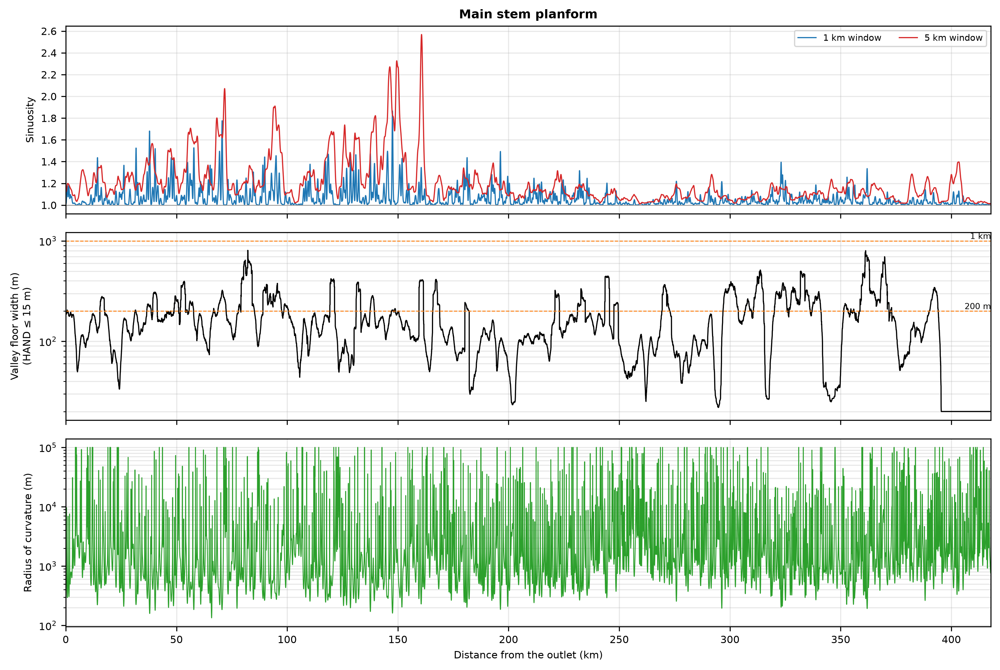

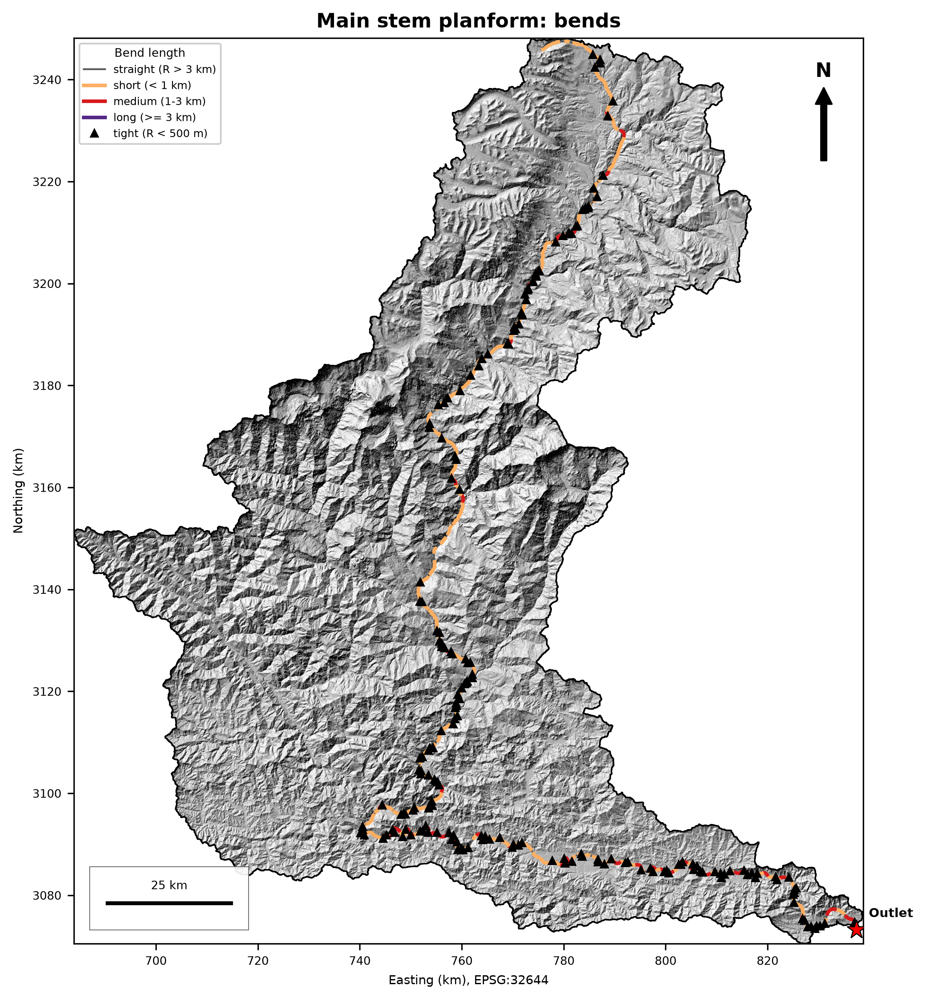

In [4]:
# ============================================================
# Cell 4: sinuosity, bends, valley floor width
# ============================================================
PATH_SIGMA_M   = 150.0     # smoothing of the channel line before measuring (removes the raster staircase)
KAPPA_SIGMA_M  = 150.0     # smoothing of the curvature
R_STRAIGHT_M   = 3000.0    # radius larger than this counts as straight
MIN_BEND_M     = 300.0     # shortest bend that is kept
BEND_BREAKS_KM = [1.0, 3.0]
BEND_LABELS    = ["short (< 1 km)", "medium (1-3 km)", "long (>= 3 km)"]
BEND_COLORS    = ["#fdae61", "#d7191c", "#542788"]
TIGHT_RADIUS_M = 500.0
SIN_WINS_KM    = [1.0, 5.0]
VALLEY_HAND_M  = 15.0      # valley floor = cells this close above the channel
CORRIDOR_M     = 3000.0    # only cells within this distance of the channel are counted
VALLEY_WIN_M   = 2000.0    # averaging length for the valley width
CONF_BREAKS_M  = [200.0, 1000.0]
CONF_LABELS    = ["confined (< 200 m)", "partly confined (200-1000 m)", "unconfined (>= 1000 m)"]

N = len(river)
z_s, d_out, area = river.z_smooth.values, river.d_out_m.values, river.area_km2.values
x_km = d_out / 1000

# ---------- smoothed line, sinuosity ----------
xs = ndimage.gaussian_filter1d(river.x.values, PATH_SIGMA_M / DS_M, mode="nearest")
ys = ndimage.gaussian_filter1d(river.y.values, PATH_SIGMA_M / DS_M, mode="nearest")
cum = np.concatenate([[0.0], np.cumsum(np.hypot(np.diff(xs), np.diff(ys)))])

def windowed_sinuosity(win_km):
    h = max(1, int(round(win_km * 1000 / DS_M / 2)))
    i = np.arange(N); lo = np.clip(i - h, 0, N - 1); hi = np.clip(i + h, 0, N - 1)
    arc = cum[hi] - cum[lo]
    chord = np.hypot(xs[hi] - xs[lo], ys[hi] - ys[lo])
    return np.where(chord > DS_M, arc / np.maximum(chord, DS_M), np.nan)

for w_ in SIN_WINS_KM:
    river[f"sin_{w_:g}km"] = windowed_sinuosity(w_)
sin_total = float(cum[-1] / np.hypot(xs[-1] - xs[0], ys[-1] - ys[0]))
print(f"Overall sinuosity of the main stem (smoothed line): {sin_total:.2f}")
print("Note: sinuosity comes from a 30 m raster line, so absolute values are approximate; compare reaches, not studies.")

# ---------- curvature ----------
dx, dy = np.gradient(xs), np.gradient(ys)
theta_h = np.unwrap(np.arctan2(dy, dx))
kappa = np.gradient(theta_h) / np.maximum(np.gradient(cum), 1.0)
kappa_s = ndimage.gaussian_filter1d(kappa, KAPPA_SIGMA_M / DS_M, mode="nearest")
river["curvature_1_per_m"] = kappa_s
river["radius_m"] = np.minimum(np.where(np.abs(kappa_s) > 1e-9, 1.0 / np.abs(kappa_s), 1e5), 1e5)

# ---------- valley floor width from HAND ----------
hand = read_grid(P.RAS / "hand_m.tif")
assert hand.shape == (H, W), "hand_m.tif is on a different grid - rerun notebook 04 Cell 3"
vmask = np.isfinite(hand) & (hand <= VALLEY_HAND_M) & ws.mask
ws.save(np.where(vmask, 1.0, np.nan).astype("float32"), P.RAS / "valley_floor.tif", nodata=0, dtype="uint8")
rf, cf = np.nonzero(vmask)
xf, yf = tf.c + (cf + 0.5) * tf.a, tf.f + (rf + 0.5) * tf.e
dist_, near_ = cKDTree(np.column_stack([x_raw, y_raw])).query(np.column_stack([xf, yf]),
                                                               distance_upper_bound=CORRIDOR_M)
okf = np.isfinite(dist_)
cnt_raw = np.bincount(near_[okf], minlength=len(x_raw)).astype(float)
ca = np.concatenate([[0.0], np.cumsum(cnt_raw * ws.res[0] * ws.res[1])])
half = VALLEY_WIN_M / 2
lo = np.searchsorted(s_raw, river.s_m.values - half, side="left")
hi = np.searchsorted(s_raw, river.s_m.values + half, side="right")
span = np.maximum(s_raw[np.minimum(hi, len(s_raw)) - 1] - s_raw[np.minimum(lo, len(s_raw) - 1)], DS_M)
valley_w = (ca[hi] - ca[lo]) / span
conf_i = np.digitize(valley_w, CONF_BREAKS_M)
river["valley_width_m"] = valley_w
river["confinement"] = [CONF_LABELS[k] for k in conf_i]
del hand, vmask, rf, cf, xf, yf
print(f"\nValley floor (HAND <= {VALLEY_HAND_M:.0f} m within {CORRIDOR_M / 1000:.0f} km of the channel): "
      f"median width {np.median(valley_w):,.0f} m | p90 {np.percentile(valley_w, 90):,.0f} m")
for k, lb in enumerate(CONF_LABELS):
    print(f"  {lb:<32}: {100 * (conf_i == k).mean():5.1f} % of the main stem length")

# ---------- bends: runs of constant turning direction ----------
sg = np.where(np.abs(kappa_s) >= 1.0 / R_STRAIGHT_M, np.sign(kappa_s), 0).astype(int)
chg = np.flatnonzero(np.diff(sg) != 0) + 1
starts, ends = np.r_[0, chg], np.r_[chg, N]
rows = []
for a, b in zip(starts, ends):
    if sg[a] == 0 or (b - a) * DS_M < MIN_BEND_M:
        continue
    arc = float(cum[b - 1] - cum[a])
    chord = float(np.hypot(xs[b - 1] - xs[a], ys[b - 1] - ys[a]))
    dth = float(abs(theta_h[b - 1] - theta_h[a]))
    k_ap = a + int(np.argmax(np.abs(kappa_s[a:b])))
    lon_a, lat_a = to_ll.transform(xs[k_ap], ys[k_ap])
    rows.append({"_a": int(a), "_b": int(b), "direction": "left" if sg[a] > 0 else "right",
                 "dist_down_km": d_out[b - 1] / 1000, "dist_up_km": d_out[a] / 1000,
                 "arc_km": arc / 1000, "chord_km": chord / 1000, "sinuosity": arc / max(chord, DS_M),
                 "deflection_deg": float(np.degrees(dth)), "min_radius_m": 1.0 / abs(kappa_s[k_ap]),
                 "mean_radius_m": arc / max(dth, 1e-3), "apex_x": float(xs[k_ap]), "apex_y": float(ys[k_ap]),
                 "apex_lon": float(lon_a), "apex_lat": float(lat_a), "apex_elev_m": float(z_s[k_ap]),
                 "apex_area_km2": float(area[k_ap]),
                 "gradient_m_per_m": float((z_s[a] - z_s[b - 1]) / max(arc, 1.0)),
                 "valley_width_m": float(np.median(valley_w[a:b]))})
bends = pd.DataFrame(rows)
bend_id = np.zeros(N, dtype=int)
if len(bends):
    bends = bends.sort_values("dist_down_km").reset_index(drop=True)
    bends.insert(0, "bend_id", np.arange(1, len(bends) + 1))
    bends["bend_class"] = [BEND_LABELS[k] for k in np.digitize(bends.arc_km, BEND_BREAKS_KM)]
    bends["tight"] = bends.min_radius_m < TIGHT_RADIUS_M
    for _, r_ in bends.iterrows():
        bend_id[int(r_["_a"]): int(r_["_b"])] = int(r_["bend_id"])
    shown = bends.drop(columns=["_a", "_b"]).round(3)
    save_table(shown, P.TAB / "06_bends.csv")
    summ = (bends.groupby("bend_class")
            .agg(n=("bend_id", "count"), total_arc_km=("arc_km", "sum"), mean_sinuosity=("sinuosity", "mean"),
                 median_min_radius_m=("min_radius_m", "median"), n_tight=("tight", "sum"))
            .reindex(BEND_LABELS).round(2))
    save_table(summ.reset_index(), P.TAB / "06_bend_classes.csv")
    display(summ)
    print(f"Bends: {len(bends)} | tight (radius < {TIGHT_RADIUS_M:.0f} m): {int(bends.tight.sum())} "
          f"| bends cover {100 * bends.arc_km.sum() * 1000 / cum[-1]:.0f} % of the line (the rest is straighter than R = {R_STRAIGHT_M / 1000:.0f} km)")
    gpd.GeoDataFrame(shown, geometry=gpd.points_from_xy(bends.apex_x, bends.apex_y), crs=ws.crs
                     ).to_file(P.VEC / "bend_apexes.gpkg", driver="GPKG")
    gpd.GeoDataFrame(shown, geometry=[LineString(np.column_stack([xs[a:b], ys[a:b]])) for a, b in zip(bends["_a"], bends["_b"])],
                     crs=ws.crs).to_file(P.VEC / "bends.gpkg", driver="GPKG")
else:
    print("No bend passed the filters - lower R_STRAIGHT_M or MIN_BEND_M")
river["bend_id"] = bend_id

# ---------- figure 1: planform profiles ----------
fig, axs = plt.subplots(3, 1, figsize=(13, 8.5), sharex=True, gridspec_kw={"hspace": 0.1})
for w_, col in zip(SIN_WINS_KM, ["tab:blue", "tab:red"]):
    axs[0].plot(x_km, river[f"sin_{w_:g}km"], lw=0.9, color=col, label=f"{w_:g} km window")
axs[0].axhline(1.0, color="0.6", lw=0.6)
axs[0].set_ylabel("Sinuosity"); axs[0].legend(fontsize=7, ncol=2, loc="upper right")
axs[0].set_title("Main stem planform", fontweight="bold")
axs[1].semilogy(x_km, np.maximum(valley_w, 20), color="k", lw=0.9)
for b_, lb in zip(CONF_BREAKS_M, ["200 m", "1 km"]):
    axs[1].axhline(b_, color="tab:orange", lw=0.7, ls="--"); axs[1].text(x_km.max(), b_, lb, fontsize=6.5, va="bottom", ha="right")
axs[1].set_ylabel(f"Valley floor width (m)\n(HAND ≤ {VALLEY_HAND_M:.0f} m)")
axs[2].semilogy(x_km, river.radius_m, color="tab:green", lw=0.7)
axs[2].set_ylabel("Radius of curvature (m)"); axs[2].set_xlabel("Distance from the outlet (km)")
axs[2].set_xlim(0, x_km.max())
for ax in axs:
    ax.grid(alpha=0.3, which="both")
fig.savefig(P.FIG / "06_planform_profiles.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

# ---------- figure 2: bends map ----------
hs = hillshade_for_plot()
e = ws.extent
fig, ax = plt.subplots(figsize=(8.6, float(np.clip(8 * (e[3] - e[2]) / (e[1] - e[0]), 5, 11))))
ax.imshow(hs, extent=e, cmap="gray", vmin=0, vmax=255)
ax.plot(xs, ys, color="0.35", lw=0.9, zorder=3)
for _, b_ in bends.iterrows():
    k = BEND_LABELS.index(b_["bend_class"])
    ax.plot(xs[int(b_["_a"]):int(b_["_b"])], ys[int(b_["_a"]):int(b_["_b"])], color=BEND_COLORS[k], lw=2.0, zorder=4)
if len(bends):
    tt = bends[bends.tight]
    ax.plot(tt.apex_x, tt.apex_y, "k^", ms=4, zorder=5)
map_furniture(ax, ws, "Main stem planform: bends")
ax.legend(handles=[Line2D([0], [0], color="0.35", lw=1, label="straight (R > 3 km)")]
          + [Line2D([0], [0], color=c, lw=2, label=l) for c, l in zip(BEND_COLORS, BEND_LABELS)]
          + [Line2D([0], [0], marker="^", color="k", ls="none", ms=4, label=f"tight (R < {TIGHT_RADIUS_M:.0f} m)")],
          loc="upper left", fontsize=6, title="Bend length", title_fontsize=6.5, framealpha=0.92)
fig.savefig(P.FIG / "06_bends_map.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

Links: 1,269 | with NaN elevation or area: 0 (expect 0)
Network length 3,919.9 km | total link drop 335,665 m | median gradient 0.068 | median ksn 193


,sub_id,stream_length_km,n_links,max_order,mean_gradient_m_per_m,max_link_gradient,mean_sinuosity_w,ksn_median,ksn_mean_w
7,8,67.5321,21,5.0,0.1197,0.5175,1.1789,467.4255,598.1814
28,29,87.3911,33,4.0,0.2071,0.7086,1.2574,450.1932,525.3827
21,22,105.0077,45,3.0,0.1603,0.5630,1.2445,441.4423,486.7936
19,20,143.5391,55,4.0,0.1478,0.4300,1.2084,392.2042,408.7325
8,9,286.7359,109,5.0,0.1520,0.4495,1.2189,391.9443,568.6878
25,26,97.1365,35,3.0,0.1232,0.4159,1.2042,354.2706,361.2535
15,16,36.1779,9,4.0,0.0818,0.3140,1.1915,290.7499,286.9557
30,31,85.7120,21,3.0,0.1156,0.2445,1.1899,278.5031,273.5438


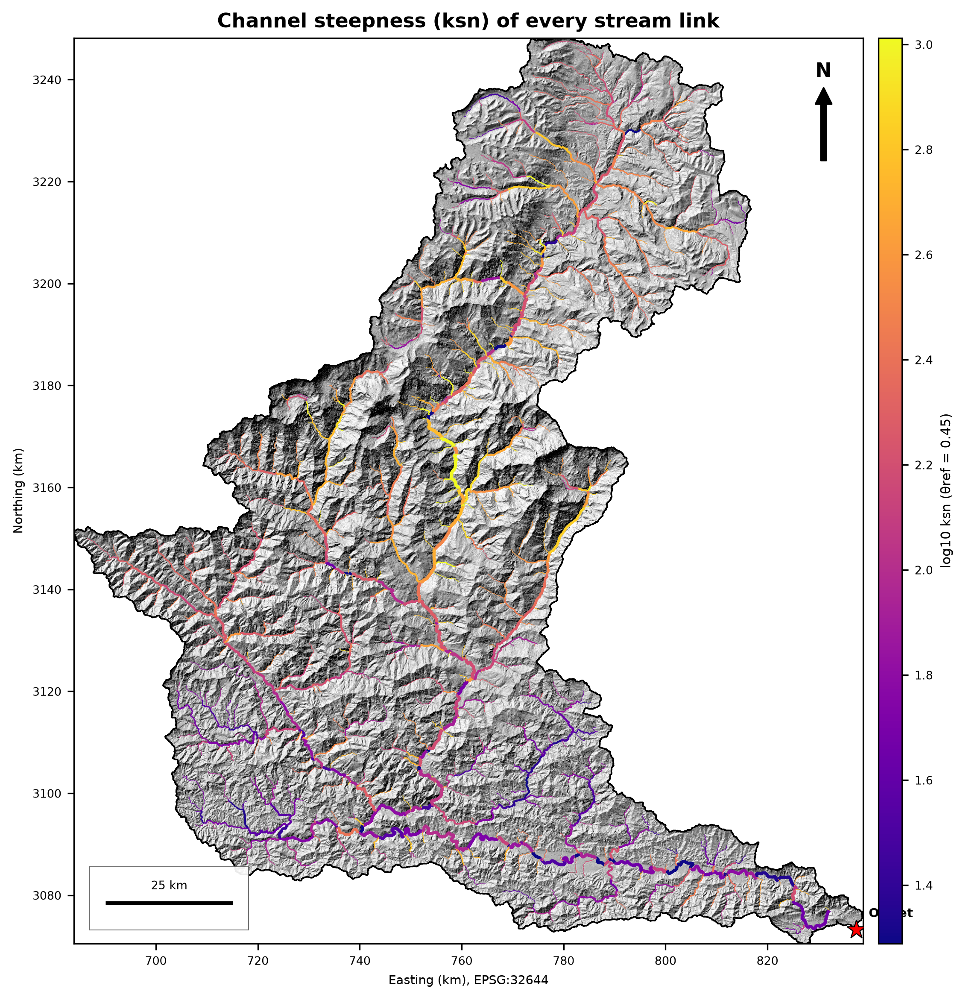

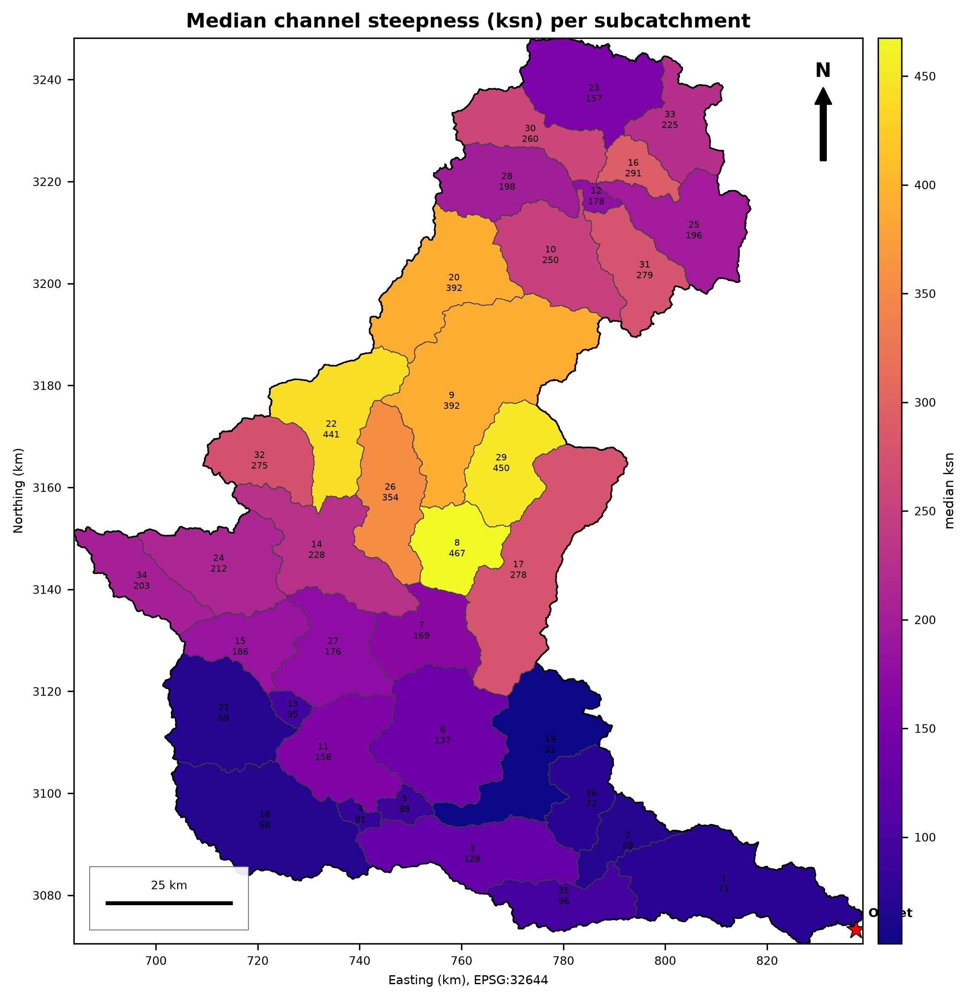

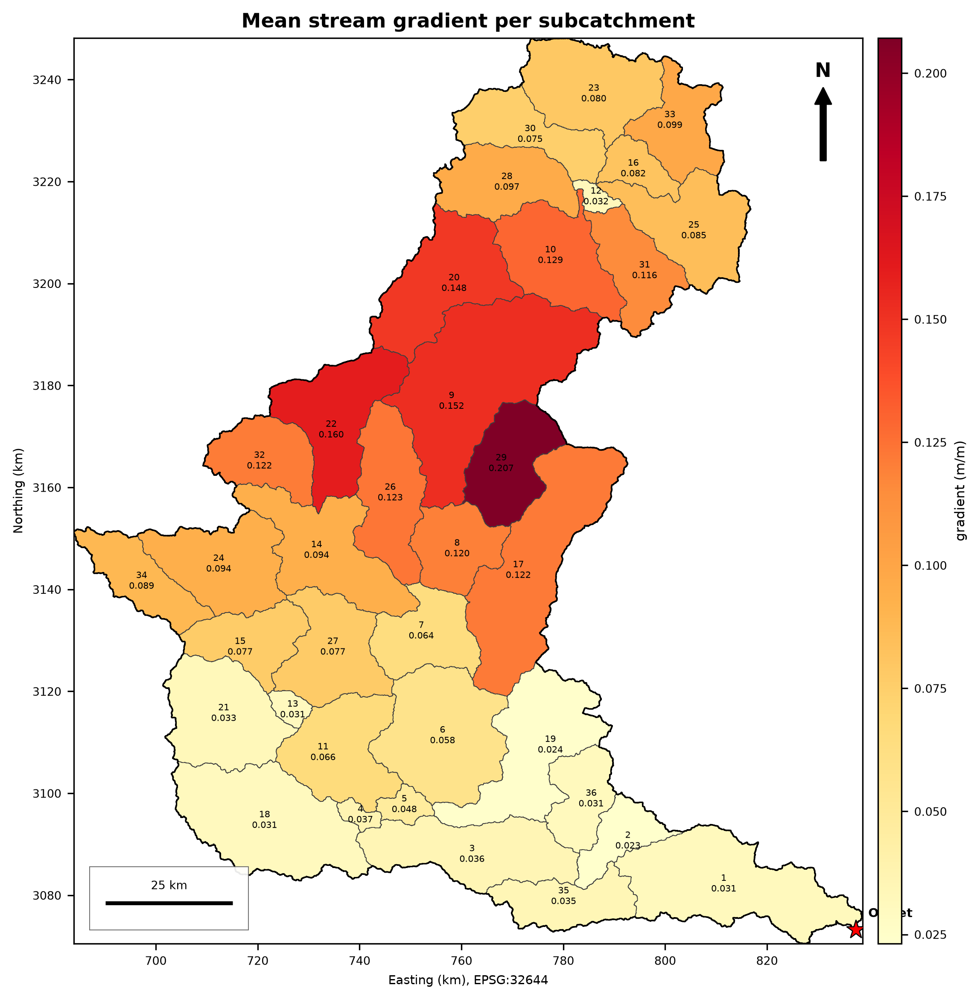

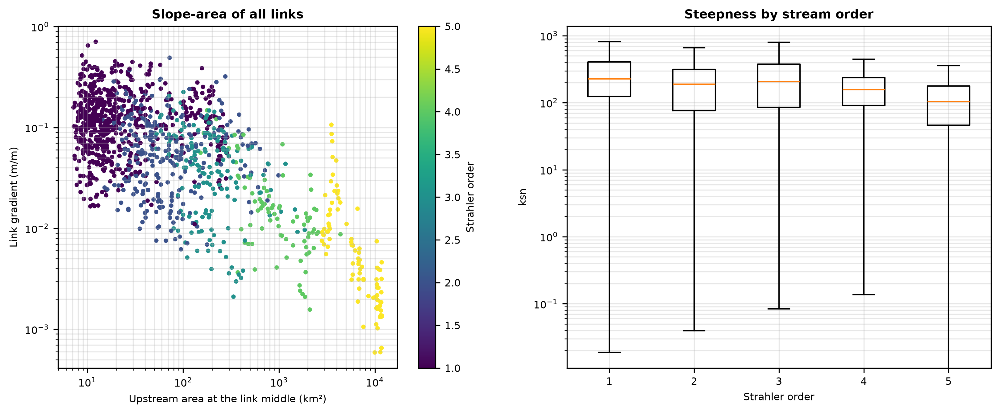

In [5]:
# ============================================================
# Cell 5: every stream link - gradient, drop, sinuosity, ksn; statistics per subcatchment
# ============================================================
MIN_LINK_M = 200.0        # shorter links get no sinuosity or ksn (too noisy at 30 m)

links = gpd.read_file(P.VEC / "streams.gpkg")
zc = ws.read(P.RAS / "dem_conditioned.tif")
acc = read_grid(P.RAS / "flow_accumulation_km2.tif")
sub = np.nan_to_num(read_grid(P.RAS / "subcatchments.tif"), nan=0).astype("int32")
assert zc.shape == acc.shape == sub.shape == (H, W), "rasters on different grids - rerun notebooks 01-04"


def main_line(g):
    return g if g.geom_type == "LineString" else max(g.geoms, key=lambda q: q.length)

lines = [main_line(g) for g in links.geometry]
e0 = np.array([ln.coords[0][:2] for ln in lines]); e1 = np.array([ln.coords[-1][:2] for ln in lines])
mids = np.array([ln.interpolate(0.5, normalized=True).coords[0][:2] for ln in lines])

def cell_of(xy):
    r_, c_ = (np.asarray(v) for v in rasterio.transform.rowcol(tf, xy[:, 0], xy[:, 1]))
    return np.clip(r_, 0, H - 1), np.clip(c_, 0, W - 1)

r0_, c0_ = cell_of(e0); r1_, c1_ = cell_of(e1); rm_, cm_ = cell_of(mids)
z0, z1, a0, a1 = zc[r0_, c0_], zc[r1_, c1_], acc[r0_, c0_], acc[r1_, c1_]
L_m = np.array([ln.length for ln in lines])
chord = np.hypot(e1[:, 0] - e0[:, 0], e1[:, 1] - e0[:, 1])
z_up, z_dn = np.fmax(z0, z1), np.fmin(z0, z1)
a_up, a_dn = np.fmin(a0, a1), np.fmax(a0, a1)
drop = z_up - z_dn
grad = drop / np.maximum(L_m, ws.res[0])
a_mid = np.sqrt(a_up * a_dn)

lk = pd.DataFrame({"link_id": links["link_id"].values, "order": links["order"].astype(float).values,
                   "sub_id": sub[rm_, cm_], "length_km": L_m / 1000, "straight_km": chord / 1000,
                   "sinuosity": L_m / np.maximum(chord, ws.res[0]), "elev_up_m": z_up, "elev_dn_m": z_dn,
                   "drop_m": drop, "gradient_m_per_m": grad, "area_up_km2": a_up, "area_dn_km2": a_dn,
                   "ksn": grad * (a_mid * 1e6) ** THETA_REF})
short = L_m < MIN_LINK_M
lk.loc[short, ["sinuosity", "ksn"]] = np.nan
lon_m, lat_m = to_ll.transform(mids[:, 0], mids[:, 1])
lk["lon_mid"], lk["lat_mid"] = np.asarray(lon_m), np.asarray(lat_m)
print(f"Links: {len(lk):,} | with NaN elevation or area: {int(lk[['elev_up_m', 'area_up_km2']].isna().any(axis=1).sum())} (expect 0)")
print(f"Network length {lk.length_km.sum():,.1f} km | total link drop {lk.drop_m.sum():,.0f} m | "
      f"median gradient {lk.gradient_m_per_m.median():.3f} | median ksn {lk.ksn.median():,.0f}")
save_table(lk.round(4), P.TAB / "06_river_links.csv")

# ---------- rasters: ksn and gradient burned along the streams ----------
def burn(vals, name):
    shp = [(g, float(v)) for g, v in zip(links.geometry, vals) if np.isfinite(v)]
    ws.save(features.rasterize(shp, out_shape=(H, W), transform=tf, fill=np.nan, dtype="float32"), P.RAS / name)
burn(lk.ksn.values, "stream_ksn.tif")
burn(lk.gradient_m_per_m.values, "stream_gradient.tif")

# ---------- per-subcatchment statistics ----------
rows = []
for sid, gp in lk[lk.sub_id > 0].groupby("sub_id"):
    L = gp.length_km.sum()
    okk, oks = gp.ksn.notna(), gp.sinuosity.notna()
    rows.append({"sub_id": int(sid), "stream_length_km": L, "n_links": len(gp), "max_order": gp["order"].max(),
                 "mean_gradient_m_per_m": gp.drop_m.sum() / (L * 1000),
                 "max_link_gradient": gp.gradient_m_per_m.max(),
                 "mean_sinuosity_w": np.average(gp.sinuosity[oks], weights=gp.length_km[oks]) if oks.any() else np.nan,
                 "ksn_median": gp.ksn.median(),
                 "ksn_mean_w": np.average(gp.ksn[okk], weights=gp.length_km[okk]) if okk.any() else np.nan})
rs = pd.DataFrame(rows).set_index("sub_id").reindex(range(1, N_SUB + 1))
rs["n_links"] = rs.n_links.fillna(0).astype(int)
rs_out = rs.reset_index().round(4)
save_table(rs_out, P.TAB / "06_subcatchment_river_stats.csv")
for c in rs.columns:
    gsub[c] = gsub["sub_id"].map(rs[c])
gsub.to_file(P.VEC / "subcatchment_river_stats.gpkg", driver="GPKG")
display(rs_out.sort_values("ksn_median", ascending=False).head(8))

# ---------- vectors ----------
lkg = gpd.GeoDataFrame(lk.round(4), geometry=lines, crs=ws.crs)
lkg.to_file(P.VEC / "river_links.gpkg", driver="GPKG")
lkg[["link_id", "order", "sub_id", "length_km", "sinuosity", "drop_m", "gradient_m_per_m", "ksn", "geometry"]].rename(
    columns={"length_km": "len_km", "sinuosity": "sinu", "gradient_m_per_m": "grad"}).to_file(P.VEC / "river_links.shp")

# ---------- map: ksn over the network ----------
hs = hillshade_for_plot()
e = ws.extent
logk = np.log10(np.where(lk.ksn > 0, lk.ksn, np.nan))
lo_, hi_ = np.nanpercentile(logk, 2), np.nanpercentile(logk, 98)
fig, ax = plt.subplots(figsize=(8.6, float(np.clip(8 * (e[3] - e[2]) / (e[1] - e[0]), 5, 11))))
ax.imshow(hs, extent=e, cmap="gray", vmin=0, vmax=255)
lw = 0.3 + 0.35 * (np.nan_to_num(lk["order"].values, nan=1) - 1)
coll = LineCollection([np.asarray(ln.coords)[:, :2] for ln in lines], array=np.ma.masked_invalid(logk),
                      cmap="plasma", norm=mcolors.Normalize(vmin=lo_, vmax=hi_), linewidths=lw, zorder=3)
ax.add_collection(coll)
cax = make_axes_locatable(ax).append_axes("right", size="3%", pad=0.12)
cb = fig.colorbar(coll, cax=cax); cb.set_label(f"log10 ksn (θref = {THETA_REF})", fontsize=7.5); cb.ax.tick_params(labelsize=6.5)
map_furniture(ax, ws, "Channel steepness (ksn) of every stream link")
fig.savefig(P.FIG / "06_ksn_network.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

choropleth("ksn_median", "06_ksn_by_subcatchment.png", "Median channel steepness (ksn) per subcatchment",
           "median ksn", cmap="plasma")
choropleth("mean_gradient_m_per_m", "06_gradient_by_subcatchment.png", "Mean stream gradient per subcatchment",
           "gradient (m/m)", cmap="YlOrRd", fmt="{:.3f}")

# ---------- link slope-area and ksn by order ----------
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
okp = (lk.gradient_m_per_m > 1e-4) & (lk.length_km * 1000 >= MIN_LINK_M)
sc = axs[0].scatter(a_mid[okp.values], lk.gradient_m_per_m[okp], c=lk["order"][okp], s=6, cmap="viridis", rasterized=True)
axs[0].set_xscale("log"); axs[0].set_yscale("log")
axs[0].set_xlabel("Upstream area at the link middle (km²)"); axs[0].set_ylabel("Link gradient (m/m)")
axs[0].set_title("Slope-area of all links", fontweight="bold"); axs[0].grid(alpha=0.3, which="both")
fig.colorbar(sc, ax=axs[0], label="Strahler order")
orders = sorted(int(o) for o in lk["order"].dropna().unique())
data = [lk.loc[(lk["order"] == o) & lk.ksn.notna(), "ksn"].values for o in orders]
axs[1].boxplot(data, showfliers=False)
axs[1].set_xticks(range(1, len(orders) + 1)); axs[1].set_xticklabels(orders)
axs[1].set_yscale("log"); axs[1].set_xlabel("Strahler order"); axs[1].set_ylabel("ksn")
axs[1].set_title("Steepness by stream order", fontweight="bold"); axs[1].grid(alpha=0.3, which="both")
fig.savefig(P.FIG / "06_link_slope_area.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

Q_SPECIFIC = 0.04 m3/s/km2 is a placeholder: power values below are indicative only.


,window_km,rank,intake_km_from_outlet,powerhouse_km_from_outlet,intake_elev_m,gross_head_m,intake_area_km2,power_MW,valley_width_m,knickzone_frac
0,1.0,1,286.1,285.1,2246.7,135.2,3528.0,159.1,77.1,1.0
1,1.0,2,277.6,276.6,1720.5,111.0,3586.7,132.8,71.7,0.6
2,1.0,3,288.0,287.0,2406.2,67.2,3472.7,77.9,102.1,0.2
3,1.0,4,281.2,280.2,1932.8,57.5,3572.8,68.5,64.7,0.0
4,1.0,5,275.5,274.5,1519.3,49.8,3615.8,60.1,73.1,0.3
5,1.0,6,283.9,282.9,2041.0,45.8,3532.2,53.9,102.6,0.0
6,1.0,7,66.5,65.6,285.0,13.0,11328.3,49.1,174.7,0.0
7,1.0,8,269.0,268.0,1296.1,36.9,3954.0,48.6,129.1,0.0
8,2.0,1,286.9,284.9,2324.8,231.8,3513.5,271.7,80.0,1.0
9,2.0,2,275.7,273.7,1551.7,115.3,3606.0,138.7,80.3,0.2



Highest theoretical power per window length:
 window_km  gross_head_m  intake_area_km2  power_MW  intake_km_from_outlet
       1.0         135.2           3528.0     159.1                  286.1
       2.0         231.8           3513.5     271.7                  286.9
       5.0         421.7           3471.4     488.3                  288.6
      10.0         633.6           3469.9     733.3                  289.3

Top tributary links by theoretical power (intake at the upstream end):


,link_id,sub_id,order,length_km,elev_up_m,drop_m,gradient_m_per_m,area_up_km2,Q_m3s,power_MW,ksn,lon_mid,lat_mid
720,721,17,4.0,11.571,3035.000000,1401.000977,0.121,183.348007,7.334000,85.677002,689.794,83.859,28.458
1200,1201,30,3.0,9.678,5054.999023,1195.999023,0.124,159.229996,6.369000,63.519001,627.680,83.857,29.143
815,816,29,3.0,8.842,2860.999023,1267.000000,0.143,149.485001,5.979000,63.172001,798.928,83.692,28.566
1135,1136,28,3.0,9.521,4993.000000,1254.000000,0.132,137.955002,5.518000,57.701000,680.109,83.807,29.068
843,844,22,3.0,6.407,2476.998047,530.997986,0.083,305.638000,12.226000,54.131001,560.392,83.390,28.606
675,676,26,3.0,11.909,1390.000000,520.000000,0.044,300.593994,12.024000,52.134998,525.540,83.537,28.410
759,760,22,3.0,6.307,1755.999023,397.998993,0.063,390.967987,15.639000,51.900002,521.603,83.367,28.537
245,246,11,4.0,4.701,563.000000,60.000999,0.013,1953.255981,78.129997,39.090000,194.317,83.451,28.010
1071,1072,25,3.0,9.802,3607.000000,332.010010,0.034,341.153015,13.646000,37.778999,321.243,83.982,29.068
1068,1069,25,3.0,7.241,4119.000000,380.001007,0.052,281.468994,11.259000,35.674999,341.872,84.053,29.009


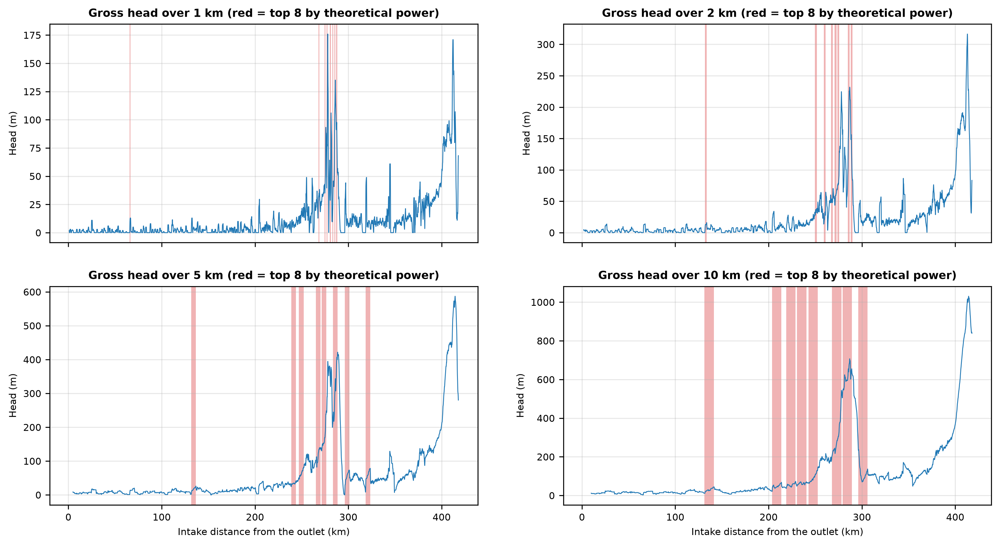

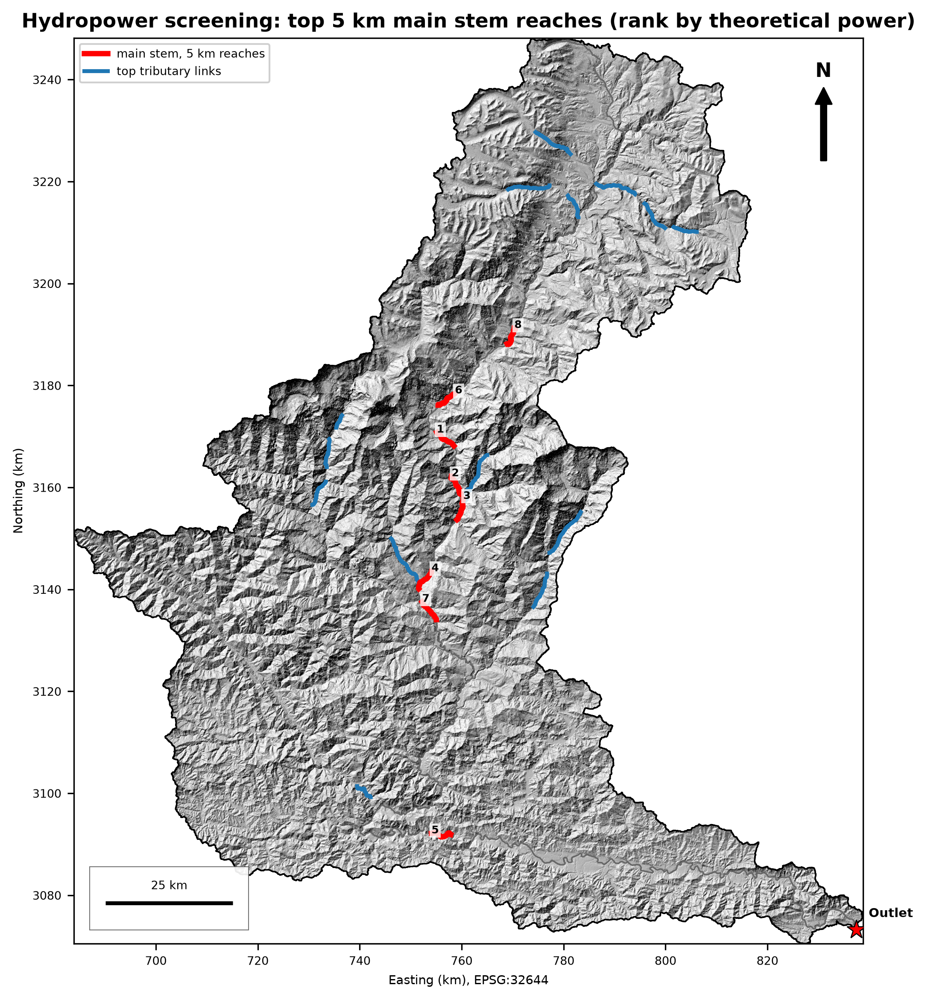

In [6]:
# ============================================================
# Cell 6: hydropower head-drop screening - SCREENING ONLY, not a design
# ============================================================
Q_SPECIFIC        = 0.04   # m3/s per km2 of upstream area  <-- PLACEHOLDER mean runoff; replace with measured flow
Q_FACTOR          = 1.0    # design discharge as a fraction of the mean flow (assumption)
EFFICIENCY        = 0.85
HEAD_WINDOWS_KM   = [1.0, 2.0, 5.0, 10.0]
MIN_AREA_HYDRO_KM2 = 100.0  # an intake needs at least this upstream area
MAX_MOD_FRAC      = 0.2    # skip reaches that overlap DEM-modified zones by more than this
TOP_N             = 8      # reaches kept per window length
MIN_SEP_KM        = 1.0    # selected reaches of one window must be at least this far apart
MAP_WINDOW_KM     = 5.0
print(f"Q_SPECIFIC = {Q_SPECIFIC} m3/s/km2 is a placeholder: power values below are indicative only.")

x, y = river.x.values, river.y.values
z_s, area, d_out = river.z_smooth.values, river.area_km2.values, river.d_out_m.values
ksn_a, valley = river.ksn.values, river.valley_width_m.values
in_kz = (river.knickzone_id.values > 0).astype(float)
mod = river.dem_modified.values.astype(float)
lon_r, lat_r = river.lon.values, river.lat.values
N = len(river)
cum_mod, cum_kz = np.concatenate([[0], np.cumsum(mod)]), np.concatenate([[0], np.cumsum(in_kz)])

rows, HEAD_CURVES = [], {}
for Lkm in HEAD_WINDOWS_KM:
    n = int(round(Lkm * 1000 / DS_M))
    if n >= N:
        continue
    i = np.arange(0, N - n)                                  # intake (upstream) index; powerhouse is at i + n
    head = z_s[i] - z_s[i + n]
    A_in = area[i]
    Q = Q_SPECIFIC * A_in * Q_FACTOR
    pw = 9.81 * EFFICIENCY * Q * head / 1000.0               # MW
    mf = (cum_mod[i + n + 1] - cum_mod[i]) / (n + 1)
    ok = (A_in >= MIN_AREA_HYDRO_KM2) & (mf <= MAX_MOD_FRAC) & (head > 0)
    HEAD_CURVES[Lkm] = (d_out[i] / 1000, head)
    sep = n + int(MIN_SEP_KM * 1000 / DS_M)
    chosen = []
    for j in np.argsort(-np.where(ok, pw, -np.inf)):
        if not ok[j]:
            break
        if all(abs(int(j) - c) >= sep for c in chosen):
            chosen.append(int(j))
            if len(chosen) == TOP_N:
                break
    for rank, j in enumerate(chosen, start=1):
        jn = j + n
        straight = float(np.hypot(x[jn] - x[j], y[jn] - y[j]))
        rows.append({"_j": j, "_n": n, "window_km": Lkm, "rank": rank,
                     "intake_km_from_outlet": d_out[j] / 1000, "powerhouse_km_from_outlet": d_out[jn] / 1000,
                     "intake_elev_m": z_s[j], "tailwater_elev_m": z_s[jn], "gross_head_m": head[j],
                     "gradient_m_per_m": head[j] / (n * DS_M), "intake_area_km2": A_in[j], "Q_m3s": Q[j],
                     "power_MW": pw[j], "channel_length_km": n * DS_M / 1000, "straight_km": straight / 1000,
                     "bypass_ratio": n * DS_M / max(straight, DS_M), "ksn_mean": float(np.nanmean(ksn_a[j:jn + 1])),
                     "valley_width_m": float(np.median(valley[j:jn + 1])),
                     "knickzone_frac": float((cum_kz[jn + 1] - cum_kz[j]) / (n + 1)), "dem_modified_frac": float(mf[j]),
                     "intake_lon": lon_r[j], "intake_lat": lat_r[j], "powerhouse_lon": lon_r[jn], "powerhouse_lat": lat_r[jn],
                     "intake_x": x[j], "intake_y": y[j], "powerhouse_x": x[jn], "powerhouse_y": y[jn]})
hp = pd.DataFrame(rows)
if len(hp):
    shown = hp.drop(columns=["_j", "_n"]).round(3)
    save_table(shown, P.TAB / "06_hydropower_main_stem.csv")
    display(shown[["window_km", "rank", "intake_km_from_outlet", "powerhouse_km_from_outlet", "intake_elev_m",
                   "gross_head_m", "intake_area_km2", "power_MW", "valley_width_m", "knickzone_frac"]].round(1))
    best = hp.loc[hp.groupby("window_km").power_MW.idxmax()]
    print("\nHighest theoretical power per window length:")
    print(best[["window_km", "gross_head_m", "intake_area_km2", "power_MW", "intake_km_from_outlet"]].round(1).to_string(index=False))
    gpd.GeoDataFrame(shown, geometry=[LineString(np.column_stack([x[j:j + n + 1], y[j:j + n + 1]]))
                                      for j, n in zip(hp["_j"], hp["_n"])], crs=ws.crs
                     ).to_file(P.VEC / "hydropower_reaches.gpkg", driver="GPKG")
    gpd.GeoDataFrame(shown, geometry=gpd.points_from_xy(hp.intake_x, hp.intake_y), crs=ws.crs
                     ).to_file(P.VEC / "hydropower_intakes.gpkg", driver="GPKG")
else:
    print("No reach passed the filters - lower MIN_AREA_HYDRO_KM2 or raise MAX_MOD_FRAC")

# ---------- tributary links ----------
dmain, _ = cKDTree(np.column_stack([x_raw, y_raw])).query(mids)
lk["on_main_stem"] = dmain < 2 * ws.res[0]
lk["Q_m3s"] = Q_SPECIFIC * lk.area_up_km2 * Q_FACTOR
lk["power_MW"] = 9.81 * EFFICIENCY * lk.Q_m3s * lk.drop_m / 1000.0
trib = lk[(lk.area_up_km2 >= MIN_AREA_HYDRO_KM2) & (lk.length_km >= 0.5) & (~lk.on_main_stem)].nlargest(15, "power_MW")
trib_out = trib[["link_id", "sub_id", "order", "length_km", "elev_up_m", "drop_m", "gradient_m_per_m",
                 "area_up_km2", "Q_m3s", "power_MW", "ksn", "lon_mid", "lat_mid"]].round(3)
save_table(trib_out, P.TAB / "06_hydropower_tributary_links.csv")
print("\nTop tributary links by theoretical power (intake at the upstream end):")
display(trib_out)
if len(trib):
    lkg.loc[trib.index].to_file(P.VEC / "hydropower_tributary_links.gpkg", driver="GPKG")

# ---------- figure 1: head curves ----------
wins = [w_ for w_ in HEAD_WINDOWS_KM if w_ in HEAD_CURVES]
ncol = 2; nrow = int(np.ceil(len(wins) / ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(14, 3.6 * nrow), sharex=True, squeeze=False)
for ax, Lkm in zip(axs.ravel(), wins):
    xk, hd = HEAD_CURVES[Lkm]
    ax.plot(xk, hd, color="tab:blue", lw=0.7)
    for _, r_ in hp[hp.window_km == Lkm].iterrows():
        ax.axvspan(r_.powerhouse_km_from_outlet, r_.intake_km_from_outlet, color="tab:red", alpha=0.35, lw=0)
    ax.set_title(f"Gross head over {Lkm:g} km (red = top {TOP_N} by theoretical power)", fontsize=9, fontweight="bold")
    ax.set_ylabel("Head (m)"); ax.grid(alpha=0.3)
for ax in axs[-1]:
    ax.set_xlabel("Intake distance from the outlet (km)")
fig.savefig(P.FIG / "06_head_drop_profiles.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

# ---------- figure 2: map ----------
hs = hillshade_for_plot()
e = ws.extent
fig, ax = plt.subplots(figsize=(8.6, float(np.clip(8 * (e[3] - e[2]) / (e[1] - e[0]), 5, 11))))
ax.imshow(hs, extent=e, cmap="gray", vmin=0, vmax=255)
ax.plot(x, y, color="0.4", lw=0.8, zorder=3)
mw = MAP_WINDOW_KM if MAP_WINDOW_KM in wins else wins[len(wins) // 2]
for _, r_ in hp[hp.window_km == mw].iterrows():
    j, n = int(r_["_j"]), int(r_["_n"])
    ax.plot(x[j:j + n + 1], y[j:j + n + 1], color="red", lw=3, zorder=5)
    ax.text(x[j], y[j], str(int(r_["rank"])), fontsize=6, fontweight="bold", zorder=6,
            bbox=dict(fc="white", ec="none", alpha=0.8, pad=1))
for idx in trib.index:
    ax.plot(*np.asarray(lines[idx].coords)[:, :2].T, color="tab:blue", lw=2.2, zorder=4)
map_furniture(ax, ws, f"Hydropower screening: top {mw:g} km main stem reaches (rank by theoretical power)")
ax.legend(handles=[Line2D([0], [0], color="red", lw=3, label=f"main stem, {mw:g} km reaches"),
                   Line2D([0], [0], color="tab:blue", lw=2.2, label="top tributary links")],
          loc="upper left", fontsize=6.5, framealpha=0.92)
fig.savefig(P.FIG / "06_hydropower_screening.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show(); plt.close(fig)

In [7]:
# ============================================================
# Cell 7: master profile, reach table, summary, inventory
# ============================================================
BLOCK_KM = 10
save_table(river.round(4), P.TAB / "06_main_stem_profile.csv")

# ---------- reach table: everything per 10 km block ----------
rows, lines_b = [], []
for b, gb in river.groupby("block"):
    if len(gb) < 3:
        continue
    L_ = float(gb.d_out_m.max() - gb.d_out_m.min())
    zu, zd = float(gb.z_smooth.iloc[0]), float(gb.z_smooth.iloc[-1])
    ids_k = gb.knickzone_id[gb.knickzone_id > 0].unique()
    rows.append({"block": int(b), "from_km": gb.d_out_m.min() / 1000, "to_km": gb.d_out_m.max() / 1000,
                 "length_km": L_ / 1000, "elev_up_m": zu, "elev_down_m": zd, "drop_m": zu - zd,
                 "gradient_m_per_m": (zu - zd) / L_, "mean_area_km2": gb.area_km2.mean(),
                 "max_order": int(gb["order"].max()), "ksn_median": gb.ksn.median(),
                 "sinuosity_5km": gb["sin_5km"].mean(), "valley_width_median_m": gb.valley_width_m.median(),
                 "confinement": gb.confinement.mode().iloc[0], "n_bends": int(gb.bend_id[gb.bend_id > 0].nunique()),
                 "n_knickzones": int(len(ids_k)), "pct_dem_modified": 100 * gb.dem_modified.mean()})
    lines_b.append(LineString(gb[["x", "y"]].values))
reach = pd.DataFrame(rows).round(4)
save_table(reach, P.TAB / "06_reaches_10km.csv")
gpd.GeoDataFrame(reach, geometry=lines_b, crs=ws.crs).to_file(P.VEC / "main_stem_reaches.gpkg", driver="GPKG")
display(reach)

# ---------- summary ----------
drop_total = float(river.z_smooth.iloc[0] - river.z_smooth.iloc[-1])
met = {"main_stem_length_km": L_TOTAL / 1000, "head_elev_m": river.z_smooth.iloc[0],
       "outlet_elev_m": river.z_smooth.iloc[-1], "total_drop_m": drop_total,
       "mean_gradient_m_per_m": drop_total / L_TOTAL, "steepest_10km_gradient": reach.gradient_m_per_m.max(),
       "slope_area_theta": theta, "slope_area_ks": ks, "slope_area_r2": r2, "ksn_median": float(np.median(river.ksn)),
       "sinuosity_overall": sin_total, "valley_width_median_m": float(river.valley_width_m.median()),
       "pct_dem_modified": 100 * float(river.dem_modified.mean()), "n_major_confluences": len(conf)}
for lb in CONF_LABELS:
    met[f"pct_length_{lb.split(' (')[0].replace(' ', '_')}"] = 100 * float((river.confinement == lb).mean())
if len(kz):
    real = kz[~kz.likely_artefact]
    met.update({"n_knickzones": len(kz), "n_knickzones_major": int((kz.kz_class == "major").sum()),
                "n_knickzones_artefact": int(kz.likely_artefact.sum()),
                "knickzone_drop_m": float(real.drop_m.sum()),
                "knickzone_drop_share_pct": 100 * float(real.drop_m.sum()) / drop_total})
if len(bends):
    met.update({"n_bends": len(bends), "n_bends_tight": int(bends.tight.sum())})
    for lb in BEND_LABELS:
        met[f"n_bends_{lb.split(' (')[0]}"] = int((bends.bend_class == lb).sum())
if len(hp):
    for Lkm, g_ in hp.groupby("window_km"):
        met[f"max_head_{Lkm:g}km_m"] = float(g_.gross_head_m.max())
        met[f"max_power_{Lkm:g}km_MW_placeholder_flow"] = float(g_.power_MW.max())
summary = pd.DataFrame({"metric": list(met), "value": [round(float(v), 4) for v in met.values()]})
save_table(summary, P.TAB / "06_river_summary.csv")
display(summary)

# ---------- inventory ----------
expected = {P.RAS: ["valley_floor.tif", "stream_ksn.tif", "stream_gradient.tif"],
            P.VEC: ["knickpoints.gpkg", "knickzones.gpkg", "bends.gpkg", "bend_apexes.gpkg", "river_links.gpkg",
                    "river_links.shp", "subcatchment_river_stats.gpkg", "main_stem_reaches.gpkg",
                    "hydropower_reaches.gpkg", "hydropower_intakes.gpkg", "hydropower_tributary_links.gpkg"]}
print(f"\n{'file':<42}{'exists':<8}{'MB':>8}")
for folder, names in expected.items():
    for n_ in names:
        p = folder / n_
        print(f"{n_:<42}{str(p.exists()):<8}{(p.stat().st_size / 1e6 if p.exists() else 0):>8.2f}")
for folder in (P.FIG, P.TAB):
    for p in sorted(folder.glob("06_*")):
        print(f"{p.name:<42}{'True':<8}{p.stat().st_size / 1e6:>8.2f}")

,block,from_km,to_km,length_km,elev_up_m,elev_down_m,drop_m,gradient_m_per_m,mean_area_km2,max_order,ksn_median,sinuosity_5km,valley_width_median_m,confinement,n_bends,n_knickzones,pct_dem_modified
0,0,0.0000,9.9914,9.9914,196.9802,185.0855,11.8947,0.0012,11857.6426,5,23.7187,1.1617,113.3857,confined (< 200 m),8,0,21.7910
1,1,10.0214,19.9814,9.9600,207.9884,196.9805,11.0079,0.0011,11814.7296,5,32.7101,1.2104,169.1243,confined (< 200 m),10,0,16.5165
2,2,20.0114,29.9714,9.9600,228.9947,207.9887,21.0060,0.0021,11753.8868,5,32.8018,1.1988,88.8439,confined (< 200 m),11,0,38.4384
3,3,30.0014,39.9914,9.9900,241.9744,228.9951,12.9793,0.0013,11697.3263,5,29.6106,1.3012,171.6773,confined (< 200 m),10,0,12.2754
4,4,40.0214,49.9814,9.9600,255.9965,241.9747,14.0217,0.0014,11613.3145,5,25.9550,1.3007,184.5788,confined (< 200 m),10,0,9.3093
5,5,50.0114,59.9714,9.9600,270.9810,255.9968,14.9842,0.0015,11437.5569,5,47.3623,1.4303,217.7002,partly confined (200-1000 m),9,0,10.5105
6,6,60.0014,69.9914,9.9900,290.9947,270.9814,20.0134,0.0020,11339.6970,5,15.9309,1.3399,174.2002,confined (< 200 m),10,0,10.4790
7,7,70.0214,79.9814,9.9600,298.9962,290.9951,8.0011,0.0008,11293.6152,5,8.0939,1.3085,187.8148,confined (< 200 m),8,0,0.0000
8,8,80.0114,89.9714,9.9600,318.9725,298.9966,19.9759,0.0020,10942.0767,5,0.4163,1.2188,316.4785,partly confined (200-1000 m),10,0,0.0000
9,9,90.0014,99.9914,9.9900,331.9787,318.9728,13.0059,0.0013,10677.8535,5,31.6480,1.4952,256.9861,partly confined (200-1000 m),8,0,10.4790


,metric,value
0,main_stem_length_km,417.8714
1,head_elev_m,5633.3504
2,outlet_elev_m,185.0855
3,total_drop_m,5448.2649
4,mean_gradient_m_per_m,0.0130
5,steepest_10km_gradient,0.0843
6,slope_area_theta,0.4143
7,slope_area_ks,74.6773
8,slope_area_r2,0.7225
9,ksn_median,106.6187



file                                      exists        MB
valley_floor.tif                          True        0.28
stream_ksn.tif                            True        1.29
stream_gradient.tif                       True        1.29
knickpoints.gpkg                          True        0.10
knickzones.gpkg                           True        0.11
bends.gpkg                                True        0.42
bend_apexes.gpkg                          True        0.22
river_links.gpkg                          True        1.47
river_links.shp                           True        0.97
subcatchment_river_stats.gpkg             True        1.55
main_stem_reaches.gpkg                    True        0.36
hydropower_reaches.gpkg                   True        0.20
hydropower_intakes.gpkg                   True        0.11
hydropower_tributary_links.gpkg           True        0.13
06_bends_map.png                          True        2.50
06_gradient_by_subcatchment.png           True        0